100%|██████████| 45.5k/45.5k [00:00<00:00, 12.4MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/aliiihussain/car-price-prediction/versions/1

--- First 5 Rows of the Dataset ---
   Car ID  Brand  Year  Engine Size Fuel Type Transmission  Mileage Condition  \
0       1  Tesla  2016          2.3    Petrol       Manual   114832       New   
1       2    BMW  2018          4.4  Electric       Manual   143190      Used   
2       3   Audi  2013          4.5  Electric       Manual   181601       New   
3       4  Tesla  2011          4.1    Diesel    Automatic    68682       New   
4       5   Ford  2009          2.6    Diesel       Manual   223009  Like New   

      Price     Model  
0  26613.92   Model X  
1  14679.61  5 Series  
2  44402.61        A4  
3  86374.33   Model Y  
4  73577.10   Mustang  

Training the Random Forest Regressor model...



--- Model Performance Metrics ---
Mean Absolute Error (MAE): 24546.57
Root Mean Squared Error (RMSE): 28446.12
R-squared Score ($R^2$): -0.0682


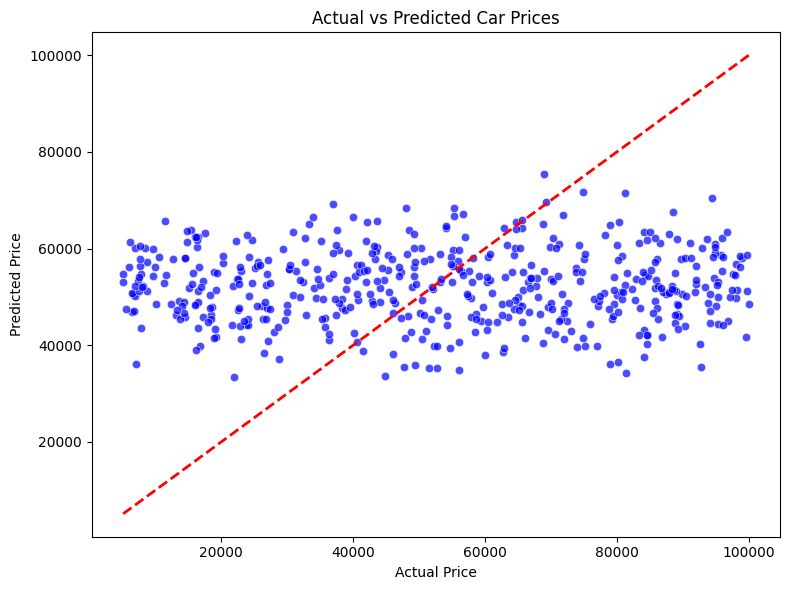


Task 3 Execution Completed Successfully!


In [1]:
!pip install kagglehub -q

import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')
print("Downloading Car Price Prediction dataset from Kaggle...")

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("aliiihussain/car-price-prediction")
print("Path to dataset files:", path)

# 2. Locate and load the CSV file into Pandas
files = os.listdir(path)
csv_file_name = [f for f in files if f.endswith('.csv')][0]
csv_file_path = os.path.join(path, csv_file_name)

df = pd.read_csv(csv_file_path)
df.columns = df.columns.str.strip()

print("\n--- First 5 Rows of the Dataset ---")
print(df.head())

# 3. Data Preprocessing & Feature Engineering
# Drop unique identifiers if they exist (e.g., 'Car ID')
if 'Car ID' in df.columns:
    df = df.drop(columns=['Car ID'])

# Drop rows with missing values
df = df.dropna()

# Handle categorical variables using One-Hot Encoding
df = pd.get_dummies(df, drop_first=True)

# Separate features (X) and target variable (Price)
target_col = [col for col in df.columns if 'price' in col.lower()][0]
X = df.drop(columns=[target_col])
y = df[target_col]

# 4. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Model Training (Random Forest Regressor)
print("\nTraining the Random Forest Regressor model...")
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 6. Evaluation
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score ($R^2$): {r2:.4f}")

# 7. Visualization: Actual vs Predicted Prices
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='b')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Car Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.tight_layout()
plt.show()

print("\nTask 3 Execution Completed Successfully!")